Name: Trang Nguyen

ID: 1622316

To address the class imbalance, the ADASYN (Adaptive Synthetic Sampling) technique is applied to generate synthetic minority class samples. The resampled dataset is then used to train and evaluate two different machine learning models:

1. Decision Tree
2. Logistic Regression

The performance of both models is assessed using common classification metrics such as accuracy, precision, recall, and F1-score. Additionally, confusion matrices and ROC curves are plotted to visualize model performance.

# Oversampling Techniques with ***ADA***ptive ***SYN***thetic Sampling (***ADASYN***)for Imbalanced Datasets:

Handling imbalanced data in Python involves techniques to address the issue where one class has significantly more instances than the other class. This can lead to biased models that perform poorly on the minority class. https://www.kaggle.com/code/jtengsun/best-techniques-and-metrics-for-imbalanced-dataset/edit
In the last two assignments you used *Random Oversampling* and *Synthetic Minority Oversampling Technique (SMOTE)* to balance the dataset. This assignment you will use Adaptive Synthetic Sampling [ADASYN] to balance the distribution of classes by increasing the number of samples in the minority class (1). It balances the distribution of classes by increasing the number of samples in the minority class.


ADASYN (Adaptive Synthetic Sampling) is an oversampling technique designed to address class imbalance by generating synthetic samples for the minority class

Videos to Watch:

[ADASYN oversampling algorithm explained](https://www.youtube.com/watch?v=KG2C-KsiNyI)

# **Description of the dataset**

The dataset contains 14,999 samples, and 9 attributes or features (6 integer, 2 float, and 2 objects), and 'left', the 'Target' variable  (what we want to predict).

The 10 variables are as follows:

1. satisfaction_level: employee satisfaction (0-1).  
2. last_evaluation: evaluated performance by the employer (0-1).
3. number_projects: numbers of projects assigned to an employee
4. average_monthly_hours: ave numbers of hours worked by an employee in a month
5. time_spent_company: employee experience measured as number of years in Co.
6. work_accident: Whether an employee has had a work accident
7. promotion_last_5years: promotion in the last 5 years
8. Departments: Employee's department
9. Salary: Salary level of the employee (low, medium and high).
10.left: 1 = employee left the Co. 0 = did not leave.

In [1]:
#import modules
import matplotlib.pyplot as plt # for plotting graphs
import seaborn as sns # for plotting graphs
import numpy as np
import pandas as pd
#MODEL
from imblearn.over_sampling import ADASYN # will not use this yet
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

Read your dataset

In [2]:
HRdf=pd.read_csv('/content/HR_Employee_churn.csv')

In this dataset, we have two types of employee, those who stayed and those that left the company. Compare their characteristics by group (the column 'left'). Here, you can find the average of both the groups using groupby() and mean() function.

In [3]:
HRdf

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Departments,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


Building a Prediction Model

Pre-Processing Data

Machine learning algorithms require numerical input data, so you need to represent categorical columns in a numerical column. In order to encode this data, you could map each value to a number. e.g. "Salary" column's value can be represented as low:0, medium:1, and high:2. This process is known as label encoding, and sklearn conveniently will do this for you using LabelEncoder.
-
You will also need to use One-HotEncoding to convert "Department" into Dummy variables.

In [4]:
# Replace 'Department' with the actual column name if there is a typo.
HRdf = pd.get_dummies(HRdf, columns=['Departments'], prefix='Dept', dtype=int)

In [5]:
from sklearn.preprocessing import LabelEncoder

# Create a LabelEncoder object
label_encoder = LabelEncoder()

# Fit the encoder to the 'Salary' column and transform it
HRdf['Encoded_salary'] = label_encoder.fit_transform(HRdf['salary'])

# Optionally, you can drop the original 'Salary' column
HRdf = HRdf.drop('salary', axis=1)

In [6]:
HRdf

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Dept_IT,Dept_RandD,Dept_accounting,Dept_hr,Dept_management,Dept_marketing,Dept_product_mng,Dept_sales,Dept_support,Dept_technical,Encoded_salary
0,0.38,0.53,2,157,3,0,1,0,0,0,0,0,0,0,0,1,0,0,1
1,0.80,0.86,5,262,6,0,1,0,0,0,0,0,0,0,0,1,0,0,2
2,0.11,0.88,7,272,4,0,1,0,0,0,0,0,0,0,0,1,0,0,2
3,0.72,0.87,5,223,5,0,1,0,0,0,0,0,0,0,0,1,0,0,1
4,0.37,0.52,2,159,3,0,1,0,0,0,0,0,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,0,0,0,0,0,0,0,0,1,0,1
14995,0.37,0.48,2,160,3,0,1,0,0,0,0,0,0,0,0,0,1,0,1
14996,0.37,0.53,2,143,3,0,1,0,0,0,0,0,0,0,0,0,1,0,1
14997,0.11,0.96,6,280,4,0,1,0,0,0,0,0,0,0,0,0,1,0,1


Take a look at the Imbalance datset i.e the 'left' feature with a bar plot

left
0    11428
1     3571
Name: count, dtype: int64


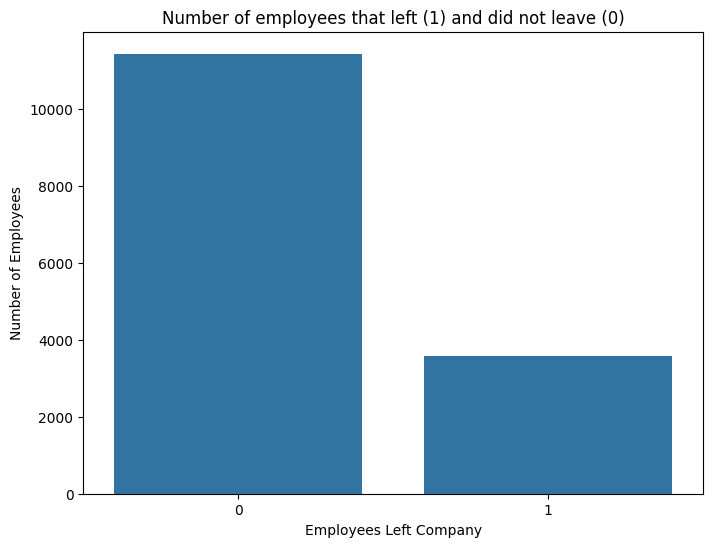

In [7]:
left_count = HRdf['left'].value_counts()
print(left_count)

plt.figure(figsize=(8, 6))  # Adjust figure size
sns.countplot(x='left', data=HRdf)  # Using countplot with seaborn
plt.title('Number of employees that left (1) and did not leave (0)')
plt.xlabel('Employees Left Company')
plt.ylabel('Number of Employees')
plt.show()

Create the input variables (features) "X" and the output variables (target) "y" arrays

In [8]:
# Create the input variables (features) "X" and the output variables (target) "y" arrays
X = HRdf.drop('left', axis=1)
y = HRdf['left']


In [9]:
X

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,Dept_IT,Dept_RandD,Dept_accounting,Dept_hr,Dept_management,Dept_marketing,Dept_product_mng,Dept_sales,Dept_support,Dept_technical,Encoded_salary
0,0.38,0.53,2,157,3,0,0,0,0,0,0,0,0,0,1,0,0,1
1,0.80,0.86,5,262,6,0,0,0,0,0,0,0,0,0,1,0,0,2
2,0.11,0.88,7,272,4,0,0,0,0,0,0,0,0,0,1,0,0,2
3,0.72,0.87,5,223,5,0,0,0,0,0,0,0,0,0,1,0,0,1
4,0.37,0.52,2,159,3,0,0,0,0,0,0,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,0,0,0,0,0,0,0,0,0,1,0,1
14995,0.37,0.48,2,160,3,0,0,0,0,0,0,0,0,0,0,1,0,1
14996,0.37,0.53,2,143,3,0,0,0,0,0,0,0,0,0,0,1,0,1
14997,0.11,0.96,6,280,4,0,0,0,0,0,0,0,0,0,0,1,0,1


Create the training and testing sets with
Import train_test_split function

In [10]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
# Assuming 'left' is the target variable and all other columns are features
X = HRdf.drop('left', axis=1)  # Features (all columns except 'left')
y = HRdf['left']  # Target variable ('left' column)


# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)  # 70% training, 30% test

In [11]:
X_test

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,Dept_IT,Dept_RandD,Dept_accounting,Dept_hr,Dept_management,Dept_marketing,Dept_product_mng,Dept_sales,Dept_support,Dept_technical,Encoded_salary
6723,0.65,0.96,5,226,2,1,0,0,0,0,0,0,1,0,0,0,0,2
6473,0.88,0.80,3,166,2,0,0,1,0,0,0,0,0,0,0,0,0,1
4679,0.69,0.98,3,214,2,0,0,0,0,0,0,0,0,0,1,0,0,1
862,0.41,0.47,2,154,3,0,0,0,0,0,0,0,0,0,1,0,0,1
7286,0.87,0.76,5,254,2,1,0,0,0,0,1,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13388,0.85,0.81,4,260,3,0,0,0,0,0,0,0,0,1,0,0,0,2
10463,0.21,0.43,2,249,3,0,0,0,0,0,0,0,1,0,0,0,0,1
5331,0.78,0.53,3,156,3,0,0,0,0,0,0,0,0,1,0,0,0,1
7499,0.93,0.58,5,238,2,0,0,0,0,0,0,0,0,0,1,0,0,2


**There are a number of classification models:**
1.   logistic regression
2.   decision tree
1.   random forest
1.   gradient-boosted tree
2.   multilayer perceptron
2.   one-vs-rest (mainly for multiple class)
1.   Naive Bayes
1.   Support Vector Machine (SVM)





Use ADASYN to balance the training data (X_train, y_train)

In [12]:
from imblearn.over_sampling import ADASYN

# Create an ADASYN object and fit it to the training data
adasyn = ADASYN(random_state=42)
X_train_adasyn, y_train_adasyn = adasyn.fit_resample(X_train, y_train)

In [13]:
X_train_adasyn

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,Dept_IT,Dept_RandD,Dept_accounting,Dept_hr,Dept_management,Dept_marketing,Dept_product_mng,Dept_sales,Dept_support,Dept_technical,Encoded_salary
0,0.100000,0.840000,7,250,4,0,0,0,0,0,0,0,0,1,0,0,0,1
1,0.570000,0.680000,4,154,3,1,0,0,0,0,0,1,0,0,0,0,0,2
2,0.390000,0.480000,2,154,3,0,0,0,0,0,0,0,0,0,0,0,1,1
3,0.910000,0.680000,4,132,4,0,0,1,0,0,0,0,0,0,0,0,0,2
4,0.820000,0.970000,5,263,5,0,0,0,0,0,0,0,0,0,0,0,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15893,0.810919,0.900634,4,218,5,0,0,0,0,0,0,0,0,0,1,0,0,1
15894,0.794580,0.978244,4,218,5,0,0,0,0,0,0,0,0,0,1,0,0,1
15895,0.842110,0.975949,4,218,5,0,0,0,0,0,0,0,0,0,0,0,0,1
15896,0.783797,0.981392,4,218,5,0,0,0,0,0,0,0,0,0,1,0,0,1


In [14]:
y_train

,left
12602,1
4889,0
1572,1
13375,0
879,1
...,...
5191,0
13418,0
5390,0
860,1


In [15]:
y_train_adasyn

,left
0,1
1,0
2,1
3,0
4,1
...,...
15893,1
15894,1
15895,1
15896,1


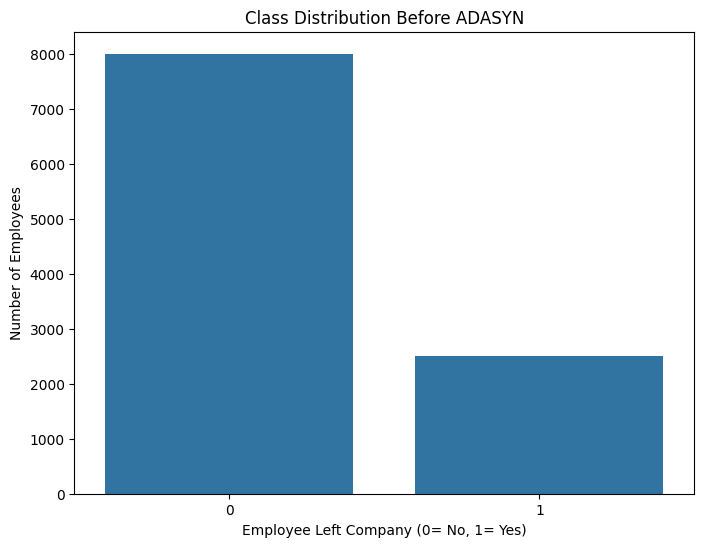

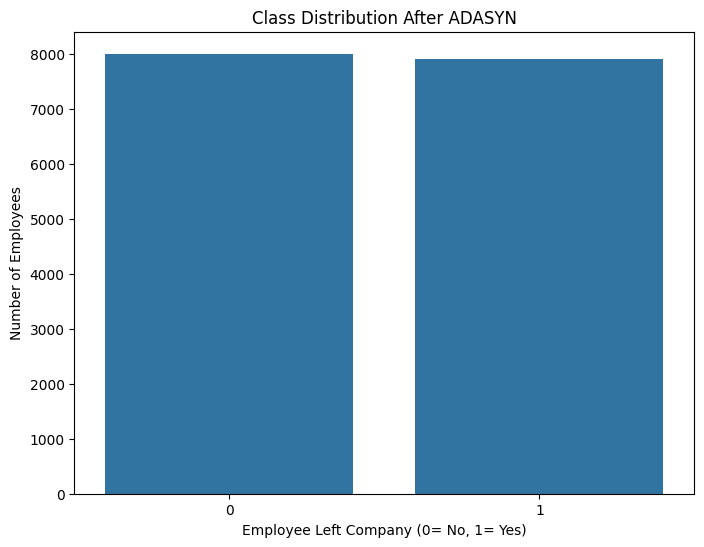

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the class distribution before ADASYN
plt.figure(figsize=(8, 6))
sns.countplot(x=y_train)
plt.title('Class Distribution Before ADASYN')
plt.xlabel('Employee Left Company (0= No, 1= Yes)')
plt.ylabel('Number of Employees')
plt.show()


# Plot the class distribution after ADASYN
plt.figure(figsize=(8, 6))
sns.countplot(x=y_train_adasyn)
plt.title('Class Distribution After ADASYN')
plt.xlabel('Employee Left Company (0= No, 1= Yes)')
plt.ylabel('Number of Employees')
plt.show()

**Model Building**

**1. Decision Tree**

Fit a classifier to both original and balanced data

In [24]:
#before ADASYN
from sklearn.tree import DecisionTreeClassifier

# Create an instance of Decision Tree Classifier
dt = DecisionTreeClassifier(random_state=42)

# Train the model using the training sets
dt.fit(X_train, y_train)

# Predict the response for the test dataset
dt_y_pred = dt.predict(X_test)

In [25]:
#after ADASYN
from sklearn.tree import DecisionTreeClassifier

# Create an instance of Decision Tree Classifier
dt = DecisionTreeClassifier(random_state=42)

# Train the model using the training sets
dt.fit(X_train_adasyn, y_train_adasyn)

# Predict the response for the test dataset
dt_adasyn_y_pred = dt.predict(X_test)

Evaluate each with accuracy, classification report, and confusion matrix

In [26]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [27]:
from sklearn import metrics
# Model Accuracy, how often is the classifier correct?
print('Decision Tree Performance Before ADASYN')
print("Accuracy:",metrics.accuracy_score(y_test, dt_y_pred))
print("\nClassification Report:\n", classification_report(y_test, dt_y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, dt_y_pred))

Decision Tree Performance Before ADASYN
Accuracy: 0.9762222222222222

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.98      0.98      3428
           1       0.94      0.96      0.95      1072

    accuracy                           0.98      4500
   macro avg       0.96      0.97      0.97      4500
weighted avg       0.98      0.98      0.98      4500


Confusion Matrix:
 [[3364   64]
 [  43 1029]]


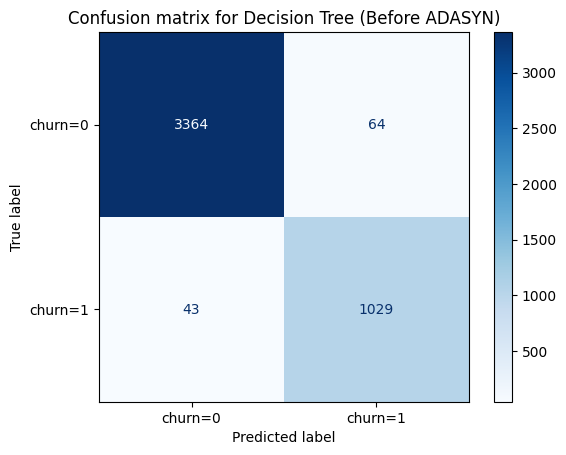

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming 'dt_adasyn_y_pred' and 'y_test' are your predictions and true labels
cm = confusion_matrix(y_test, dt_y_pred)

# Create the ConfusionMatrixDisplay object
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['churn=0', 'churn=1'])

# Plot the confusion matrix
disp.plot(cmap=plt.cm.Blues, values_format='g')  # Customize colormap and format
plt.title('Confusion matrix for Decision Tree (Before ADASYN)')
plt.show()

In [ ]:
from sklearn import metrics
# Model Accuracy, how often is the classifier correct?
print('Decision Tree Performance After ADASYN')
print("Accuracy:",metrics.accuracy_score(y_test, dt_adasyn_y_pred))
print("\nClassification Report:\n", classification_report(y_test, dt_adasyn_y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test,dt_adasyn_y_pred))

Decision Tree Performance After ADASYN
Accuracy: 0.9491111111111111

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.95      0.97      3428
           1       0.85      0.96      0.90      1072

    accuracy                           0.95      4500
   macro avg       0.92      0.95      0.93      4500
weighted avg       0.95      0.95      0.95      4500


Confusion Matrix:
 [[3247  181]
 [  48 1024]]


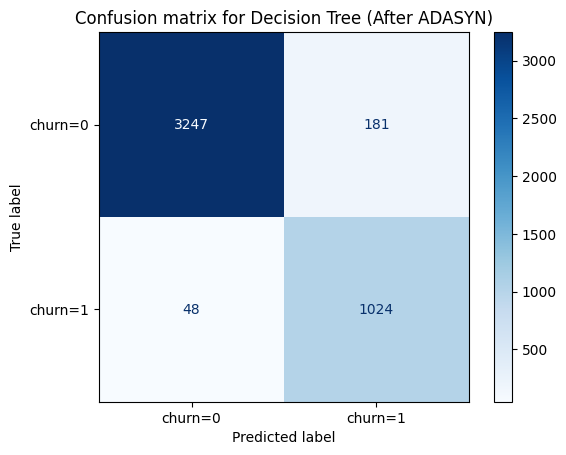

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming 'dt_adasyn_y_pred' and 'y_test' are your predictions and true labels
cm = confusion_matrix(y_test, dt_adasyn_y_pred)

# Create the ConfusionMatrixDisplay object
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['churn=0', 'churn=1'])

# Plot the confusion matrix
disp.plot(cmap=plt.cm.Blues, values_format='g')  # Customize colormap and format
plt.title('Confusion matrix for Decision Tree (After ADASYN)')
plt.show()

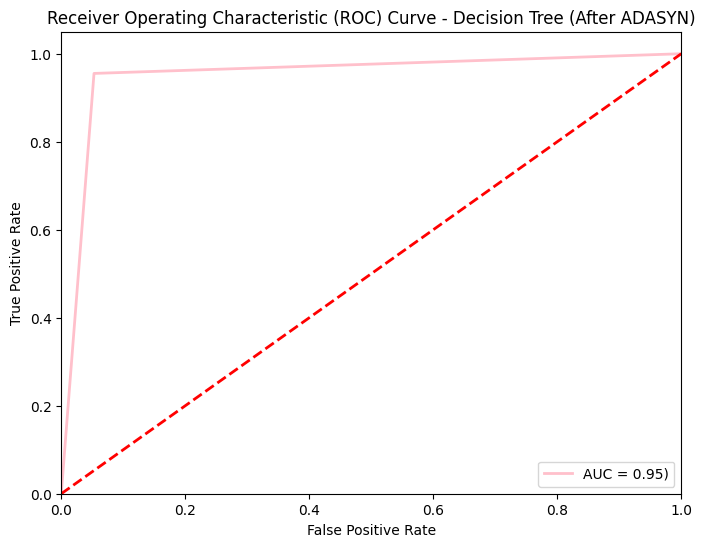

In [ ]:
import matplotlib.pyplot as plt
# Calculate ROC curve and AUC for the Decision Tree model after ADASYN
fpr, tpr, thresholds = metrics.roc_curve(y_test, dt_adasyn_y_pred)
roc_auc = metrics.auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='pink', lw=2, label=f'AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Decision Tree (After ADASYN)')
plt.legend(loc="lower right")
plt.show()

**2. Logistic Regression**

In [17]:
#before ADASYN
# Import the Scikit Learn Logistic Regression module
from sklearn.linear_model import LogisticRegression

#Create an instance of Logistic regression Classifier
lr = LogisticRegression(solver='lbfgs', max_iter=1000)

#Train the model using the training sets
lr.fit(X_train,y_train)

#Predict the response for test dataset
lry_pred = lr.predict(X_test)

In [18]:
# Import the Scikit Learn Logistic Regression module
from sklearn.linear_model import LogisticRegression

#Create an instance of Logistic regression Classifier
lr = LogisticRegression(solver='lbfgs', max_iter=1000)

#Train the model using the training sets
lr.fit(X_train_adasyn, y_train_adasyn)

#Predict the response for test dataset
lr_adasyn_y_pred = lr.predict(X_test)

In [19]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [20]:
from sklearn import metrics
# Model Accuracy, how often is the classifier correct?
print('Logistic Regression Performance Before ADASYN')
print("Accuracy:",metrics.accuracy_score(y_test, lry_pred))
print("\nClassification Report:\n", classification_report(y_test, lry_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, lry_pred))

Logistic Regression Performance Before ADASYN
Accuracy: 0.7595555555555555

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.92      0.85      3428
           1       0.49      0.24      0.32      1072

    accuracy                           0.76      4500
   macro avg       0.64      0.58      0.59      4500
weighted avg       0.72      0.76      0.73      4500


Confusion Matrix:
 [[3165  263]
 [ 819  253]]


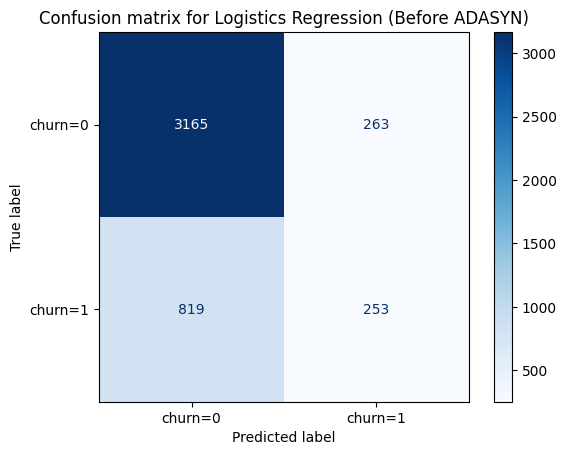

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming 'dt_adasyn_y_pred' and 'y_test' are your predictions and true labels
cm = confusion_matrix(y_test, lry_pred)

# Create the ConfusionMatrixDisplay object
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['churn=0', 'churn=1'])

# Plot the confusion matrix
disp.plot(cmap=plt.cm.Blues, values_format='g')  # Customize colormap and format
plt.title('Confusion matrix for Logistics Regression (Before ADASYN)')
plt.show()

In [21]:
from sklearn import metrics
# Model Accuracy, how often is the classifier correct?
print('Logistic Regression Performance After ADASYN')
print("Accuracy:",metrics.accuracy_score(y_test, lr_adasyn_y_pred))
print("\nClassification Report:\n", classification_report(y_test, lr_adasyn_y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, lr_adasyn_y_pred))

Logistic Regression Performance After ADASYN
Accuracy: 0.7651111111111111

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.79      0.84      3428
           1       0.51      0.67      0.58      1072

    accuracy                           0.77      4500
   macro avg       0.70      0.73      0.71      4500
weighted avg       0.79      0.77      0.78      4500


Confusion Matrix:
 [[2723  705]
 [ 352  720]]


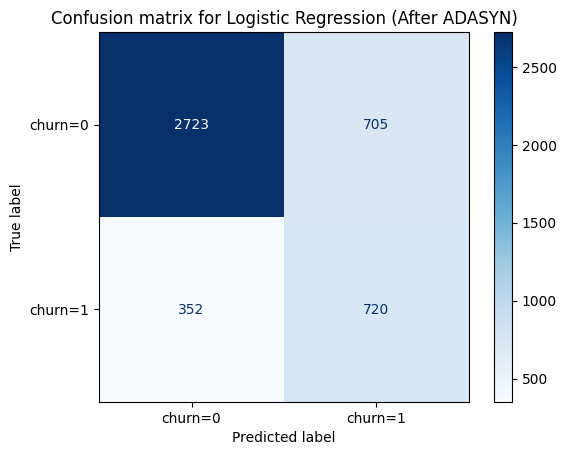

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming 'dt_adasyn_y_pred' and 'y_test' are your predictions and true labels
cm = confusion_matrix(y_test, lr_adasyn_y_pred)

# Create the ConfusionMatrixDisplay object
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['churn=0', 'churn=1'])

# Plot the confusion matrix
disp.plot(cmap=plt.cm.Blues, values_format='g')  # Customize colormap and format
plt.title('Confusion matrix for Logistic Regression (After ADASYN)')
plt.show()

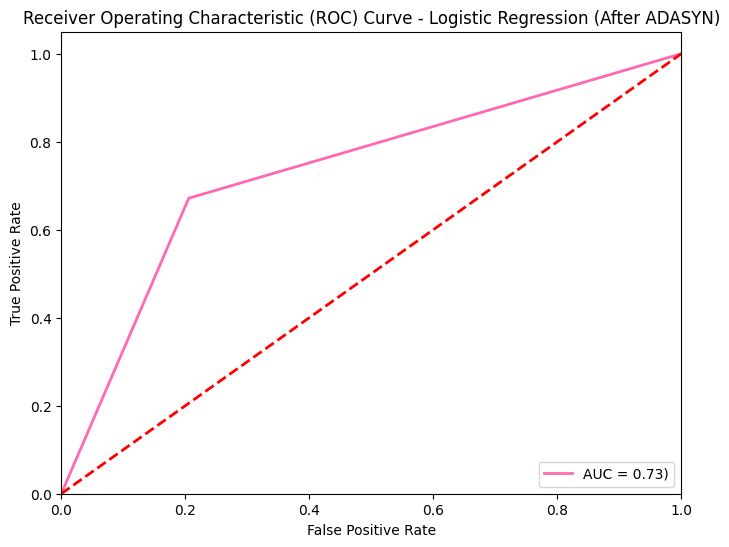

In [30]:
import matplotlib.pyplot as plt
# Calculate ROC curve and AUC for the Decision Tree model after ADASYN
fpr, tpr, thresholds = metrics.roc_curve(y_test, lr_adasyn_y_pred)
roc_auc = metrics.auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='hotpink', lw=2, label=f'AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Logistic Regression (After ADASYN)')
plt.legend(loc="lower right")
plt.show()

**Display results side by side in a comparison table**

| Model | ADASYN | Accuracy | Precision (Class 0) | Precision (Class 1) | Recall (Class 0) | Recall (Class 1) | F1-Score (Class 0) | F1-Score (Class 1) |
|---|---|---|---|---|---|---|---|---|
| Decision Tree | Before | 0.98 | 0.99 | 0.94 | 0.98 | 0.96 | 0.98 | 0.95 |
| Decision Tree | After | 0.95 | 0.99 | 0.85 | 0.95 | 0.96 | 0.97 | 0.90 |
| Logistic Regression | Before | 0.76 | 0.79 | 0.49 | 0.92 | 0.24 | 0.85 | 0.32 |
| Logistic Regression | After | 0.77 | 0.89 | 0.51 | 0.79 | 0.67 | 0.84 | 0.58 |